# ISING MODEL MONTE CARLO

In [1]:
from matplotlib import pyplot as plt
import numpy as np
from numba import jit

In [2]:
L = 10 # dimension of lattice
N = 1000 # number of monte-carlo sweeps

kB = 1.


In [3]:
@jit(nopython = True)
def monte_carlo_sweeps(L, N, T):
    M = np.zeros(N) #magnetization sotred at the end of each sweep
    S_history = np.zeros((N, L, L)) #stores lattice states over sweeps
    #lattice of spins
    S = np.ones((L,L))
    for n in range(0, N):
        for i in range(0, L):
            for j in range(0, L):
                #corner points########################################
                #top left corner
                if i == 0 and j == 0:
                    left_spin = S[0 , L-1]
                    top_spin = S[L-1 , 0]
                    right_spin = S[0, 1]
                    bottom_spin = S[1, 0]
                #top right corner
                elif i==0 and j == L-1:
                    left_spin = S[0 , L-2]
                    top_spin = S[L-1 , L-1]
                    right_spin = S[0, 0]
                    bottom_spin = S[1, L-1]
                #bottom left corner
                elif i==L-1 and j == 0:
                    left_spin = S[L-1 , L-1]
                    top_spin = S[L-2 , 0]
                    right_spin = S[L-1, 1]
                    bottom_spin = S[0, 0]
                #bottom right corner
                elif i==L-1 and j ==L-1:
                    left_spin = S[L-1 , L-2]
                    top_spin = S[L-2 , L-1]
                    right_spin = S[L-1, 0]
                    bottom_spin = S[0, L-1]
                
                ##################################################################
                #left edge
                elif 1<=i<=L-2 and j==0:
                    left_spin = S[i , L-1]
                    top_spin = S[i-1 , j]
                    right_spin = S[i, j+1]
                    bottom_spin = S[i+1, j]

                #right edge
                elif 1<=i<=L-2 and j==L-1:
                    left_spin = S[i , j-1]
                    top_spin = S[i-1 , j]
                    right_spin = S[i, 0]
                    bottom_spin = S[i+1, j]

                #top edge
                elif i==0 and 1<=j<=L-2:
                    left_spin = S[i , j-1]
                    top_spin = S[L-1 , j]
                    right_spin = S[i, j+1]
                    bottom_spin = S[i+1, j]

                #bottom edge
                elif i==L-1 and 1<=j<=L-2:
                    left_spin = S[i , j-1]
                    top_spin = S[i-1 , j]
                    right_spin = S[i, j+1]
                    bottom_spin = S[0, j]

                #interior points###########################################################
                else:
                    left_spin = S[i , j-1]
                    top_spin = S[i-1 , j]
                    right_spin = S[i, j+1]
                    bottom_spin = S[i+1, j]

                #energy to flip
                E_flip = 2*S[i,j]*(left_spin + top_spin + right_spin + bottom_spin)
                
                #check flipping chance
                if E_flip<=0:
                    S[i,j] = -S[i,j]
                else:
                    r = np.random.random()
                    if r<= np.exp(-E_flip/(kB*T)):
                        S[i,j] = - S[i,j]
                        

        M[n] = np.sum(S)
        S_history[n] = S
        #print('Finished sweep: '+str(n+1))
    
    return M, S_history


In [22]:
T = 3.
M, S_history = monte_carlo_sweeps(L, N, T)
m = M/(L**2.)

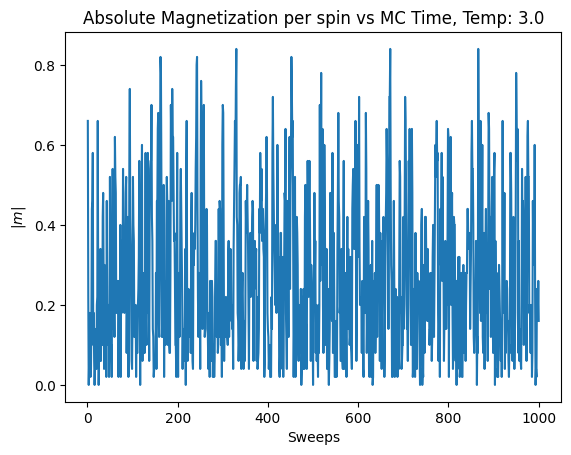

In [23]:
plt.plot(np.arange(1,N+1, dtype = np.float64), np.abs(m))
plt.xlabel('Sweeps')
plt.ylabel(r'$|m|$')
plt.title('Absolute Magnetization per spin vs MC Time, Temp: '+str(T))
plt.show()

In [24]:
np.mean(np.abs(m)[500:])

0.26696000000000003

## Make Movie

In [8]:
from matplotlib.animation import PillowWriter

In [25]:
def plot_frame(index, ax):
    
    lattice_plot = ax[0]
    magnetization_per_spin_plot = ax[1]
  

    lattice_plot.imshow(S_history[index], cmap ='binary')
    lattice_plot.tick_params(bottom = False, left = False, labelbottom = False, labelleft = False)
    lattice_plot.set_ylabel('Lattice', fontsize = 20)

    magnetization_per_spin_plot.plot(np.arange(1,index+2, dtype = np.float64), np.abs(m)[0:index+1])
    magnetization_per_spin_plot.grid()
    magnetization_per_spin_plot.set_xlabel('Monte Carlo Sweeps')
    magnetization_per_spin_plot.set_ylabel(r'$|m|$')
    magnetization_per_spin_plot.set_ylim([-0.1, 1.1])
    


    

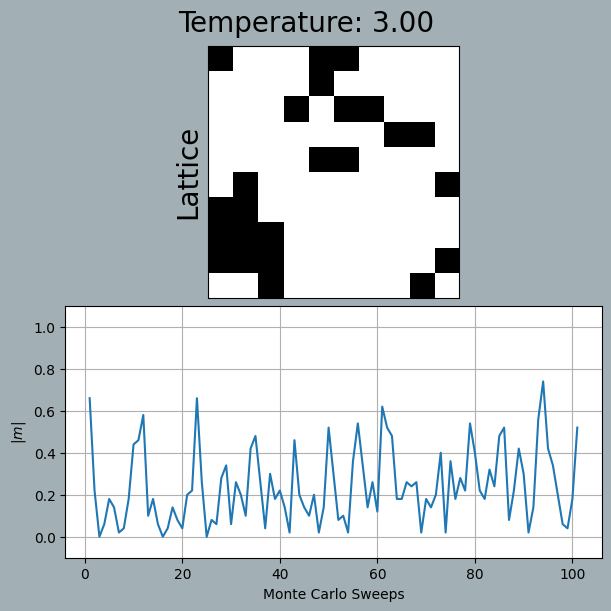

In [26]:
fig, ax = plt.subplots(2,1, figsize=(6, 6), constrained_layout=True)
fig.suptitle('Temperature: '+str("%.2f" %(T)), c='black', fontsize=20)
fig.patch.set_facecolor("#a2afb4")
plot_frame(100,ax)
plt.show()

In [12]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

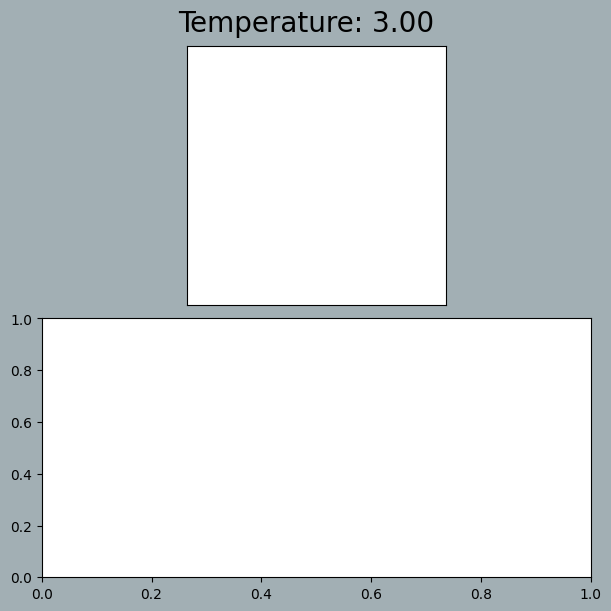

In [27]:
fig, ax = plt.subplots(2,1, figsize=(6, 6), constrained_layout=True)
fig.patch.set_facecolor("#a2afb4")

with writer.saving(fig, 'ising_model_T'+str("%.2f" %(T))+'.gif',100):
    for n in range(0, N):
        if n%4 == 0:
            fig.suptitle('Temperature: '+str("%.2f" %(T)), c='black', fontsize=20)
            plot_frame(n, ax)
            writer.grab_frame()
            ax[0].clear()
            ax[1].clear()
            